# 🌸 TP3: Supervised Classification — Fisher's Iris Flower Dataset
### Academic Laboratory Practical Work | Chapter IV: Classification
**Course:** Machine Learning & Statistical Pattern Recognition  
**Environment Support:** Google Colab & VS Code Compatible  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saoula2026/ml_univ/blob/main/TP3/iris_dataset/TP3_Iris.ipynb)

---

## 🎯 Practical Work Objectives & Syllabus Coverage
In this practical session (**TP3**), we conduct an exhaustive, rigorous empirical and theoretical study of **11 foundational classification algorithms** introduced in **Chapter IV: Classification** applied to a classic **multi-class classification** problem ($C=3$):

1. **Logistic Regression** (Multinomial Softmax & Cross-Entropy)
2. **Polynomial Logistic Regression** (Non-linear Feature Space Expansion)
3. **Simple Perceptron** (Rosenblatt's Linear Classifier with One-vs-Rest)
4. **Multi-Layer Perceptron (MLP)** (Feedforward Neural Network with Softmax Output)
5. **Decision Tree with Information Gain (Entropy)** (Shannon Entropy Multi-Class Splits)
6. **Decision Tree with Gini Impurity** (Multi-Class Gini Metric)
7. **Random Forest Classifier** (Bootstrap Aggregation & Subspace Randomization)
8. **K-Nearest Neighbors ($k$-NN)** (Non-parametric Distance-based Nearest Neighbor Voting)
9. **Gaussian Naive Bayes** (Multivariate Gaussian Likelihoods with Class Independence)
10. **Linear Support Vector Machine (Linear SVM)** (One-vs-Rest Soft Margin Hyperplanes)
11. **Non-Linear Support Vector Machine (RBF Kernel SVM)** (Infinite-Dimensional Hilbert Mapping)

### Pedagogical Pipeline
* **Section 1: Exploratory Data Analysis (EDA):** Morphological feature distributions, class balance, correlation heatmap, and interactive multi-dimensional scatter visualizers.
* **Section 2: Data Preprocessing & Validation Setup:** Collinearity analysis, hold-out stratified splitting, and strict leakage-free standard scaling.
* **Section 3: Model Training, Theoretical Derivations & Full Multi-Metric Evaluation:** Mathematical formulations from Chapter IV, 5-fold stratified cross-validation, side-by-side Confusion Matrix and One-vs-Rest (OvR) ROC curves for each classifier.
* **Section 4: Hyperparameter Optimization:** Systematic grid search with cross-validation (`GridSearchCV`) for Random Forest and Support Vector Machine.
* **Section 5: Final Model Comparison & Academic Conclusion:** Comprehensive synthesis benchmark table, comparative metric plots, and in-depth academic conclusion on classifier inductive biases and dataset geometry.

In [1]:
# ==============================================================================
# SECTION 0: Environment Setup & Library Imports
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

# Core scientific computing and data manipulation
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Set Plotly renderer for universal notebook compatibility (VS Code & Colab)
pio.renderers.default = "notebook_connected"

# Scikit-Learn: Datasets & Validation
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Scikit-Learn: Classification Models
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Scikit-Learn: Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

# Global plot formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14

# Set global random state for reproducible experiments
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ All required libraries successfully imported.")
print(f"📊 NumPy Version: {np.__version__}")
print(f"🐼 Pandas Version: {pd.__version__}")

✅ All required libraries successfully imported.
📊 NumPy Version: 2.4.6
🐼 Pandas Version: 3.0.3


## 1. Data Loading & Exploratory Data Analysis (EDA)

The **Iris Flower Dataset** was introduced by the British statistician and biologist Ronald A. Fisher in his 1936 paper *"The use of multiple measurements in taxonomic problems"*.

The dataset comprises:
* **Instances:** 150 biological specimens (50 specimens per species).
* **Attributes:** 4 morphological features measured in centimeters:
  1. `sepal length (cm)`
  2. `sepal width (cm)`
  3. `petal length (cm)`
  4. `petal width (cm)`
* **Target Classes:** 3 distinct species of Iris:
  * `0`: **Iris-setosa** (linearly separable from the other two species)
  * `1`: **Iris-versicolor** (shares geometric boundaries with Virginica)
  * `2`: **Iris-virginica** (partially overlapping with Versicolor in sepal dimensions)

In [2]:
# Load the Iris dataset from scikit-learn
raw_iris = load_iris(as_frame=True)
df = raw_iris.frame.copy()

# Add human-readable species label
species_map = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df['species'] = df['target'].map(species_map)

# Display structural summary
print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} columns (4 features + target + species label)")
df.head(10)

Dataset Shape: 150 samples, 6 columns (4 features + target + species label)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa
5,5.4,3.9,1.7,0.4,0,Setosa
6,4.6,3.4,1.4,0.3,0,Setosa
7,5.0,3.4,1.5,0.2,0,Setosa
8,4.4,2.9,1.4,0.2,0,Setosa
9,4.9,3.1,1.5,0.1,0,Setosa


In [3]:
# Summary information: Data types, memory footprint, and non-null counts
print("--- Dataframe Information ---")
df.info()

print("\n--- Missing Values Audit ---")
missing_counts = df.isnull().sum()
print(f"Total missing values across all cells: {missing_counts.sum()}")

print("\n--- Duplicate Rows Audit ---")
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

--- Dataframe Information ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB

--- Missing Values Audit ---
Total missing values across all cells: 0

--- Duplicate Rows Audit ---
Total duplicate rows: 1


In [4]:
# Descriptive statistical summary of numerical features
df.drop(columns=['target', 'species']).describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
sepal length (cm),5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


--- Target Class Distribution ---


,Count,Percentage (%)
species,,
Setosa,50,33.33
Versicolor,50,33.33
Virginica,50,33.33


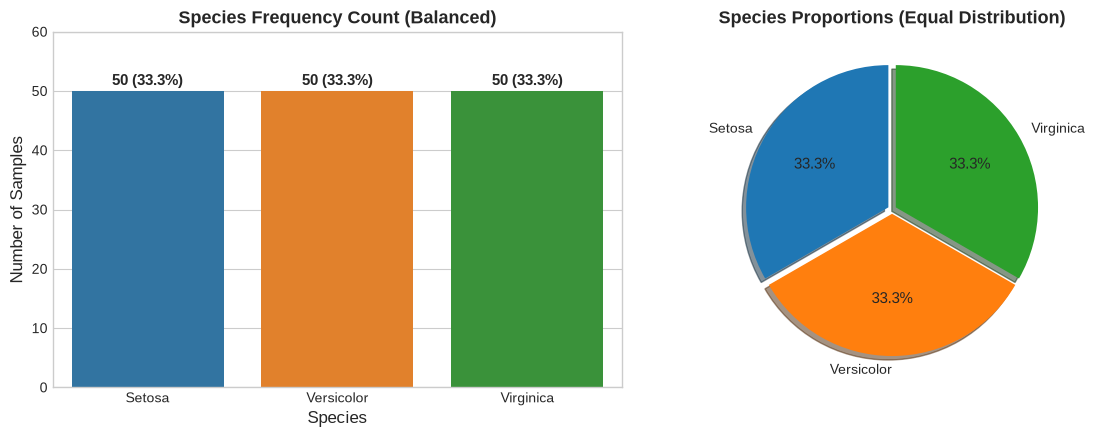

In [5]:
# Target Class Balance Analysis
class_counts = df['species'].value_counts()
class_percentages = df['species'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})
print("--- Target Class Distribution ---")
display(class_summary)

# Visualizing target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Countplot
sns.barplot(x=class_summary.index, y=class_summary['Count'], palette=['#1f77b4', '#ff7f0e', '#2ca02c'], ax=axes[0])
axes[0].set_title("Species Frequency Count (Balanced)", fontweight='bold')
axes[0].set_ylabel("Number of Samples")
axes[0].set_xlabel("Species")
for i, count in enumerate(class_summary['Count']):
    axes[0].text(i, count + 1, f"{count} ({class_percentages.iloc[i]:.1f}%)", ha='center', fontweight='bold')
axes[0].set_ylim(0, 60)

# Pie chart
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=['#1f77b4', '#ff7f0e', '#2ca02c'],
    startangle=90,
    explode=[0.03, 0.03, 0.03],
    shadow=True
)
axes[1].set_title("Species Proportions (Equal Distribution)", fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# Interactive Exploratory Scatter Plot (Plotly)
fig_eda = px.scatter(
    df,
    x='petal length (cm)',
    y='petal width (cm)',
    color='species',
    symbol='species',
    color_discrete_map={'Setosa': '#1f77b4', 'Versicolor': '#ff7f0e', 'Virginica': '#2ca02c'},
    hover_data=['sepal length (cm)', 'sepal width (cm)'],
    title="Interactive EDA: Petal Length vs. Petal Width across Iris Species",
    labels={'petal length (cm)': 'Petal Length (cm)', 'petal width (cm)': 'Petal Width (cm)'},
    template='plotly_white',
    marginal_x='violin',
    marginal_y='box'
)
fig_eda.update_layout(width=900, height=550)
fig_eda.show()

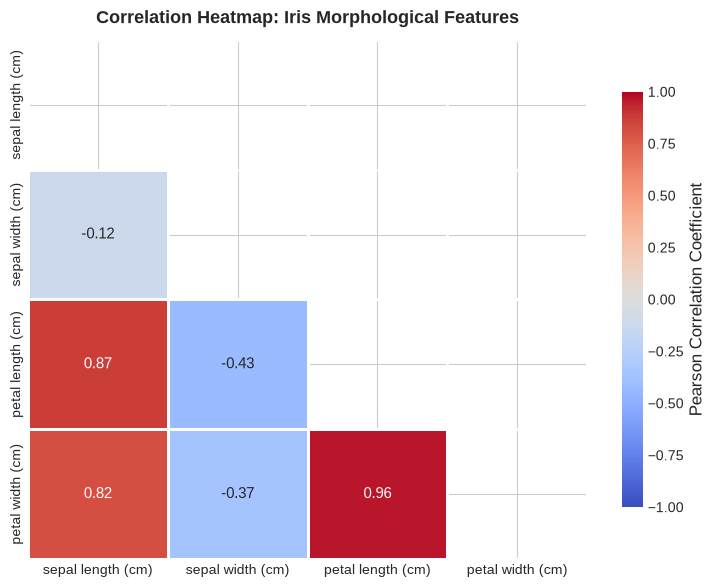

In [7]:
# Correlation Heatmap among morphological features
features_only = df.drop(columns=['target', 'species'])
corr_matrix = features_only.corr()

plt.figure(figsize=(7.5, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1.0,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Heatmap: Iris Morphological Features", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

> [!NOTE]
> ### 🔍 Critical EDA & Multicollinearity Findings:
> 1. **Strong Linear Collinearities:**
>    * `petal length (cm)` $\leftrightarrow$ `petal width (cm)` exhibits an extremely high positive correlation ($r = 0.96$).
>    * `sepal length (cm)` $\leftrightarrow$ `petal length (cm)` displays strong correlation ($r = 0.87$).
>    * Conversely, `sepal width (cm)` is negatively correlated with `petal length (cm)` ($r = -0.43$).
> 2. **Cluster Geometry:**
>    * *Iris-setosa* forms a distinct, completely isolated cluster characterized by short, narrow petals ($L < 2.0\text{ cm}, W < 0.8\text{ cm}$).
>    * *Iris-versicolor* and *Iris-virginica* are adjacent and partially overlap near petal length $\approx 4.8 - 5.1\text{ cm}$, requiring non-linear boundaries or soft margins to resolve subtle boundary instances.

## 2. Data Preprocessing

### 2.1 Multicollinearity & Feature Retention
In this dataset, `petal length` and `petal width` are strongly correlated ($r = 0.96$). While in production systems one might consider dropping one feature, in this academic benchmark we retain all 4 canonical features to evaluate how different classifiers handle collinear multi-dimensional spaces.

### 2.2 Target Encoding
* `0`: **Setosa**
* `1`: **Versicolor**
* `2`: **Virginica**

### 2.3 Hold-out Validation Strategy (Section 9 of Chapter IV)
According to **Section 9 of Chapter IV**, supervised model validation requires an unbiased hold-out partition:
$$\mathcal{D} = \mathcal{D}_{\text{train}} \cup \mathcal{D}_{\text{test}}, \quad |\mathcal{D}_{\text{train}}| = 120 \, (80\%), \quad |\mathcal{D}_{\text{test}}| = 30 \, (20\%)$$
* **Stratified Sampling:** Using `stratify=y` guarantees that each of the three species comprises exactly 40 training samples and 10 test samples, preserving class balance.

### 2.4 Feature Scaling (`StandardScaler`) & Data Leakage Prevention
Although all 4 features share the same physical unit ($\text{cm}$), their variances differ: `petal length` varies over $[1.0, 6.9]$ while `sepal width` varies over $[2.0, 4.4]$.
* **Strict Leakage Prevention:** `StandardScaler` computes sample mean $\mu_{\text{train}}$ and standard deviation $\sigma_{\text{train}}$ **strictly on $X_{\text{train}}$**.
$$X_{\text{train, scaled}} = \frac{X_{\text{train}} - \mu_{\text{train}}}{\sigma_{\text{train}}}, \quad X_{\text{test, scaled}} = \frac{X_{\text{test}} - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

In [8]:
# 1. Separate feature matrix X and target vector y
X = df.drop(columns=['target', 'species'])
y = df['target']

# Target encoding dictionary
print("Target Encoding Dictionary:", species_map)

# 2. Train-Test Split (80% Train, 20% Test) with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training feature matrix shape: {X_train.shape} ({X_train.shape[0]} samples)")
print(f"Testing feature matrix shape:  {X_test.shape} ({X_test.shape[0]} samples)")

# Verify balanced stratified distributions
print("Train Class Distribution (samples per class):\n", y_train.value_counts().to_dict())
print("Test Class Distribution (samples per class):\n", y_test.value_counts().to_dict())

Target Encoding Dictionary: {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
Training feature matrix shape: (120, 4) (120 samples)
Testing feature matrix shape:  (30, 4) (30 samples)
Train Class Distribution (samples per class):
 {0: 40, 2: 40, 1: 40}
Test Class Distribution (samples per class):
 {0: 10, 2: 10, 1: 10}


In [9]:
# 3. Feature Scaling (StandardScaler) strictly avoiding data leakage
scaler = StandardScaler()

# Fit strictly on X_train, transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify empirical scaling properties: mean ~ 0, std ~ 1
print("Scaled X_train - Mean across features:", np.round(X_train_scaled.mean(axis=0), 4))
print("Scaled X_train - Std across features: ", np.round(X_train_scaled.std(axis=0), 4))
print("Scaled X_test  - Mean across features:", np.round(X_test_scaled.mean(axis=0), 4))

Scaled X_train - Mean across features: [-0.  0.  0.  0.]
Scaled X_train - Std across features:  [1. 1. 1. 1.]
Scaled X_test  - Mean across features: [ 0.01    0.1007 -0.0341 -0.0373]


## 3. Classification Models (Training, Theory, Formulas & Full Evaluation)

### Multi-Class Evaluation Metrics Framework (Chapter IV, Section 9)
For multi-class classification with $C=3$ classes, we evaluate performance using both global metrics and One-vs-Rest (OvR) decompositions.

Let $CM_{ij}$ denote the number of instances truly in class $i$ predicted as class $j$. For each class $c \in \{0, 1, 2\}$:
$$TP_c = CM_{cc}$$
$$FP_c = \sum_{j \neq c} CM_{jc}$$
$$FN_c = \sum_{j \neq c} CM_{cj}$$
$$TN_c = \sum_{j \neq c} \sum_{k \neq c} CM_{jk} = N - (TP_c + FP_c + FN_c)$$

The exact multi-class metrics documented in Chapter IV are:

$$\text{Accuracy} = \frac{\sum_{c=1}^C TP_c}{N} = \frac{\text{Trace}(CM)}{N}$$

$$\text{Precision}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TP_c}{TP_c + FP_c}$$

$$\text{Recall}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TP_c}{TP_c + FN_c}$$

$$\text{Specificity}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TN_c}{TN_c + FP_c}$$

$$\text{F1-Score}_{\text{weighted}} = 2 \cdot \frac{\text{Precision}_{\text{weighted}} \cdot \text{Recall}_{\text{weighted}}}{\text{Precision}_{\text{weighted}} + \text{Recall}_{\text{weighted}}}$$

$$\text{ROC-AUC}_{\text{OvR, weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \text{AUC}_c$$

In [10]:
# Helper: Multi-Class Specificity Calculation
def compute_multiclass_specificity(y_true, y_pred, average='weighted'):
    """
    Computes Specificity (True Negative Rate) for multi-class classification
    using One-vs-Rest (OvR) decomposition.
    """
    classes = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    specificities = []
    supports = []
    for i in range(len(classes)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - (tp + fp + fn)
        spec_i = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        specificities.append(spec_i)
        supports.append(cm[i, :].sum())
    
    if average == 'macro':
        return float(np.mean(specificities))
    elif average == 'weighted':
        return float(np.average(specificities, weights=supports))
    else:
        return specificities

# Master Evaluation Framework Function for Iris
results_summary = []

def evaluate_and_plot_iris_model(
    model_name,
    model,
    X_train_s,
    y_train,
    X_test_s,
    y_test,
    is_perceptron=False
):
    """
    Trains an Iris classifier, executes 5-fold stratified cross-validation, prints full metrics,
    and visualizes the 3x3 Confusion Matrix and One-vs-Rest ROC curves side-by-side.
    """
    # 1. 5-Fold Stratified Cross-Validation on Training Data
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train_s, y_train, cv=cv_strategy, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    # 2. Fit model on full training set
    model.fit(X_train_s, y_train)

    # 3. Predictions on Train and Test sets
    y_train_pred = model.predict(X_train_s)
    y_test_pred = model.predict(X_test_s)

    # 4. Multi-class Probability Estimation for ROC-AUC
    if is_perceptron:
        # Perceptron lacks predict_proba; apply Softmax to decision scores
        scores = model.decision_function(X_test_s)
        exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
        y_test_prob = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    else:
        y_test_prob = model.predict_proba(X_test_s)

    # 5. Metric Calculations
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    precision = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
    specificity = compute_multiclass_specificity(y_test, y_test_pred, average='weighted')
    auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average='weighted')

    cm = confusion_matrix(y_test, y_test_pred)

    # Append to global benchmark registry
    record = {
        'Model': model_name,
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        '5-Fold CV Mean Accuracy': round(cv_mean, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4),
        'Specificity': round(specificity, 4),
        'ROC-AUC': round(auc, 4)
    }
    results_summary.append(record)

    # 6. Console Report
    print(f"================================================================================")
    print(f"📊 PERFORMANCE REPORT: {model_name.upper()}")
    print(f"================================================================================")
    print(f"• Training Set Accuracy:           {train_acc:.4f} ({train_acc*100:.2f}%)")
    print(f"• 5-Fold Stratified CV Accuracy:   {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"• Test Set Accuracy:               {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"• Precision (Weighted):            {precision:.4f}")
    print(f"• Recall (Weighted):               {recall:.4f}")
    print(f"• Specificity (Weighted TNR):      {specificity:.4f}")
    print(f"• F1-Score (Weighted):             {f1:.4f}")
    print(f"• ROC-AUC (OvR Weighted):          {auc:.4f}")

    # 7. Side-by-Side Visualizations (Matplotlib / Seaborn)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # Left: Confusion Matrix Heatmap
    class_labels = ['Setosa', 'Versicolor', 'Virginica']
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[0],
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    axes[0].set_title(f"Confusion Matrix — {model_name}", fontweight='bold', pad=10)
    axes[0].set_xlabel("Predicted Species", fontweight='bold')
    axes[0].set_ylabel("True Species", fontweight='bold')

    # Right: Multi-Class One-vs-Rest (OvR) ROC Curves
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    for c, (cls_name, col) in enumerate(zip(class_labels, colors)):
        y_test_bin = (y_test == c).astype(int)
        fpr_c, tpr_c, _ = roc_curve(y_test_bin, y_test_prob[:, c])
        auc_c = roc_auc_score(y_test_bin, y_test_prob[:, c])
        axes[1].plot(fpr_c, tpr_c, color=col, lw=2.0, label=f'{cls_name} vs. Rest (AUC = {auc_c:.4f})')

    axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.50)')
    axes[1].set_xlim([-0.02, 1.02])
    axes[1].set_ylim([-0.02, 1.05])
    axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
    axes[1].set_ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
    axes[1].set_title(f'Multi-Class OvR ROC — {model_name} (Weighted AUC={auc:.4f})', fontweight='bold', pad=10)
    axes[1].legend(loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()

    return record, y_test_prob

### 3.1 Multinomial Logistic Regression

#### Theoretical Foundations & Formulas (Chapter IV)
In multi-class settings ($C=3$), Logistic Regression utilizes the **Softmax (Multinomial Logit) function** to compute class posterior probabilities:
$$P(Y=c|X=x) = \frac{e^{w_c^T x + b_c}}{\sum_{k=1}^C e^{w_k^T x + b_k}}, \quad c \in \{0, 1, 2\}$$

The model is optimized by minimizing the **Categorical Cross-Entropy Loss** with $L_2$ regularization:
$$\mathcal{L}(W, b) = - \frac{1}{N} \sum_{i=1}^N \sum_{c=1}^C \mathbb{I}(y_i = c) \ln P(Y=c|x_i) + \frac{1}{2C} \sum_{c=1}^C \|w_c\|_2^2$$

📊 PERFORMANCE REPORT: LOGISTIC REGRESSION
• Training Set Accuracy:           0.9583 (95.83%)
• 5-Fold Stratified CV Accuracy:   0.9583 ± 0.0264
• Test Set Accuracy:               0.9333 (93.33%)
• Precision (Weighted):            0.9333
• Recall (Weighted):               0.9333
• Specificity (Weighted TNR):      0.9667
• F1-Score (Weighted):             0.9333
• ROC-AUC (OvR Weighted):          0.9967


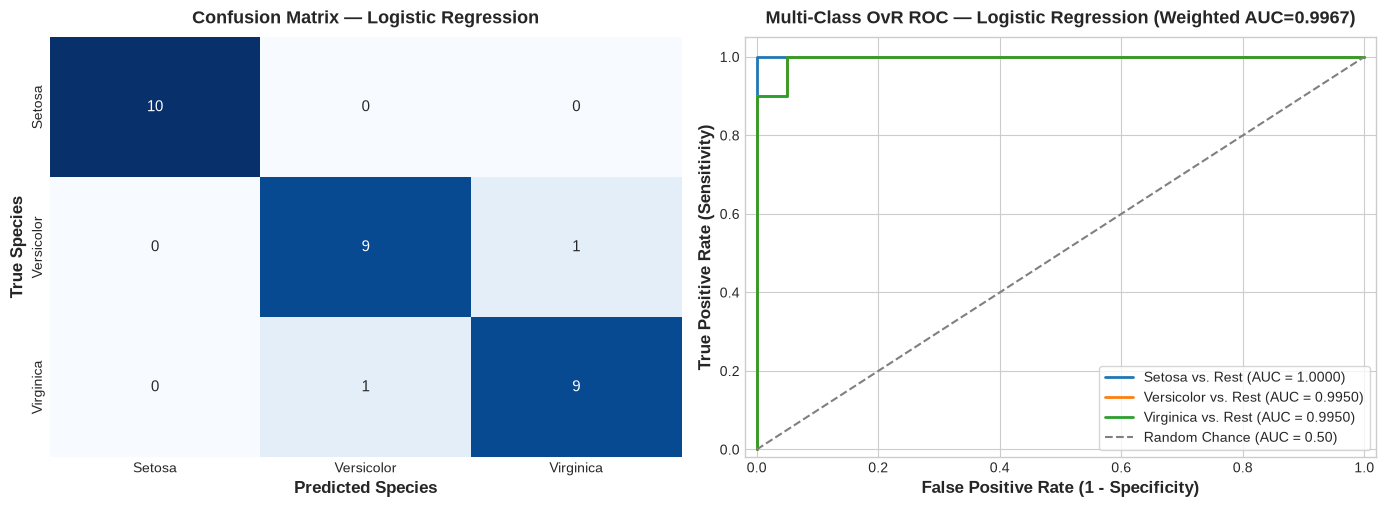

In [11]:
# 3.1 Multinomial Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
_, lr_probs = evaluate_and_plot_iris_model(
    "Logistic Regression",
    lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.2 Polynomial Logistic Regression

#### Theoretical Foundations & Formulas (Chapter IV)
By mapping the 4-dimensional input $x = [x_1, x_2, x_3, x_4]^T$ into degree-$2$ polynomial space $\phi(x)$, we introduce pairwise interaction and quadratic terms:
$$\phi(x) = \left[ x_1, x_2, x_3, x_4, \, x_1^2, x_1 x_2, \dots, x_4^2 \right]^T \in \mathbb{R}^{14}$$

The multinomial softmax operates over non-linear feature combinations:
$$P(Y=c|x) = \frac{e^{w_c^T \phi(x) + b_c}}{\sum_{k=1}^C e^{w_k^T \phi(x) + b_k}}$$
This allows the classifier to construct quadratic decision boundaries capable of cleanly separating the overlapping regions of *Versicolor* and *Virginica*.

📊 PERFORMANCE REPORT: POLYNOMIAL LOGISTIC REGRESSION
• Training Set Accuracy:           0.9833 (98.33%)
• 5-Fold Stratified CV Accuracy:   0.9667 ± 0.0167
• Test Set Accuracy:               0.9333 (93.33%)
• Precision (Weighted):            0.9333
• Recall (Weighted):               0.9333
• Specificity (Weighted TNR):      0.9667
• F1-Score (Weighted):             0.9333
• ROC-AUC (OvR Weighted):          0.9967


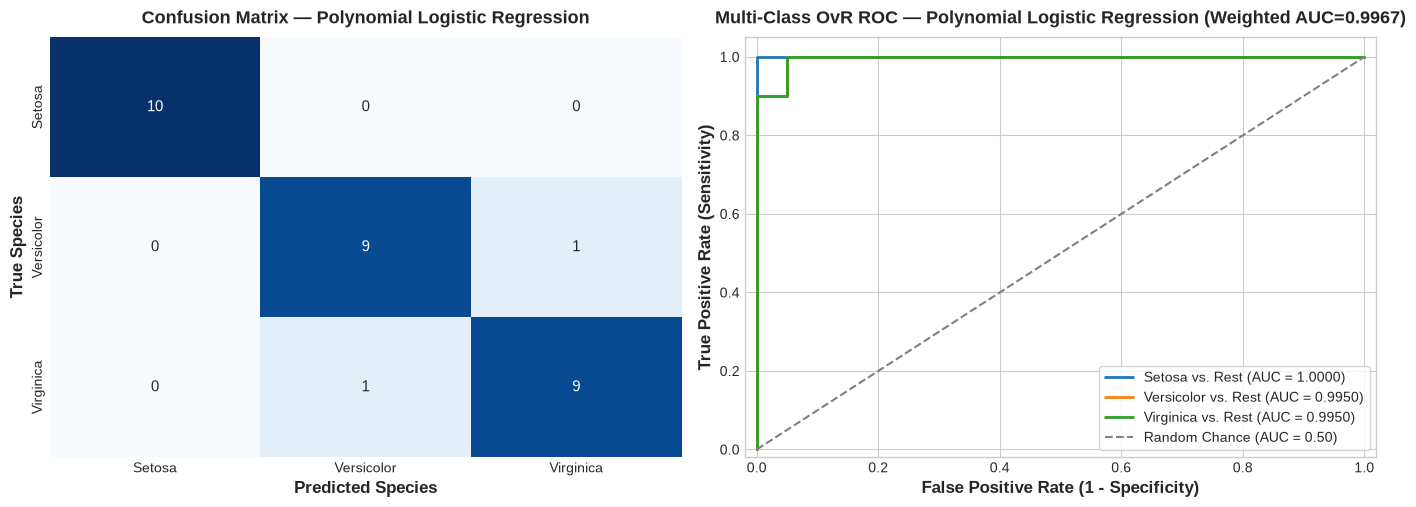

In [12]:
# 3.2 Polynomial Logistic Regression (Degree = 2)
poly_lr_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('log_reg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

_, poly_lr_probs = evaluate_and_plot_iris_model(
    "Polynomial Logistic Regression",
    poly_lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.3 Simple Perceptron

#### Theoretical Foundations & Formulas (Chapter IV)
For multi-class classification, the **Perceptron** trains $C=3$ independent linear units using the **One-vs-Rest (OvR)** architecture. Each neuron evaluates:
$$z_c = w_c^T x + b_c, \quad c \in \{0, 1, 2\}$$

**Decision Rule:**
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} (w_c^T x + b_c)$$

**Weight Update:** For every misclassified training point $(x_i, y_i)$:
$$w_{y_i} \leftarrow w_{y_i} + \eta x_i, \quad w_{\hat{y}_i} \leftarrow w_{\hat{y}_i} - \eta x_i$$

📊 PERFORMANCE REPORT: SIMPLE PERCEPTRON
• Training Set Accuracy:           0.9000 (90.00%)
• 5-Fold Stratified CV Accuracy:   0.9000 ± 0.0624
• Test Set Accuracy:               0.8667 (86.67%)
• Precision (Weighted):            0.8750
• Recall (Weighted):               0.8667
• Specificity (Weighted TNR):      0.9333
• F1-Score (Weighted):             0.8653
• ROC-AUC (OvR Weighted):          0.9800


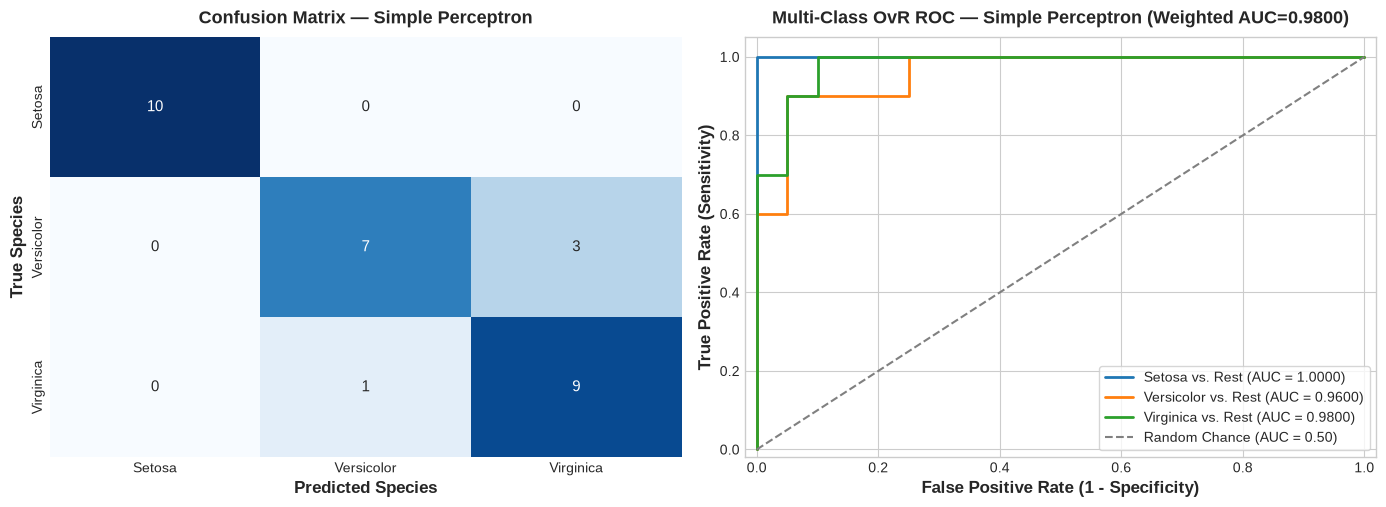

In [13]:
# 3.3 Simple Perceptron
perceptron_model = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
_, perc_probs = evaluate_and_plot_iris_model(
    "Simple Perceptron",
    perceptron_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    is_perceptron=True
)

### 3.4 Multi-Layer Perceptron (MLP)

#### Theoretical Foundations & Formulas (Chapter IV)
The **Multi-Layer Perceptron (MLP)** utilizes hidden layers equipped with non-linear activation functions ($g(z) = \max(0, z)$) followed by a **Softmax output layer**:

$$a^{(1)} = \text{ReLU}\left( W^{(1)} x + b^{(1)} \right)$$
$$a^{(2)} = \text{ReLU}\left( W^{(2)} a^{(1)} + b^{(2)} \right)$$
$$\hat{y}_c = P(Y=c|x) = \frac{e^{z_c^{(3)}}}{\sum_{k=1}^C e^{z_k^{(3)}}}, \quad \text{where } z^{(3)} = W^{(3)} a^{(2)} + b^{(3)}$$

The network weights are iteratively adjusted using Adam backpropagation to minimize categorical cross-entropy.

📊 PERFORMANCE REPORT: MULTI-LAYER PERCEPTRON (MLP)
• Training Set Accuracy:           0.9833 (98.33%)
• 5-Fold Stratified CV Accuracy:   0.9500 ± 0.0312
• Test Set Accuracy:               0.9667 (96.67%)
• Precision (Weighted):            0.9697
• Recall (Weighted):               0.9667
• Specificity (Weighted TNR):      0.9833
• F1-Score (Weighted):             0.9666
• ROC-AUC (OvR Weighted):          1.0000


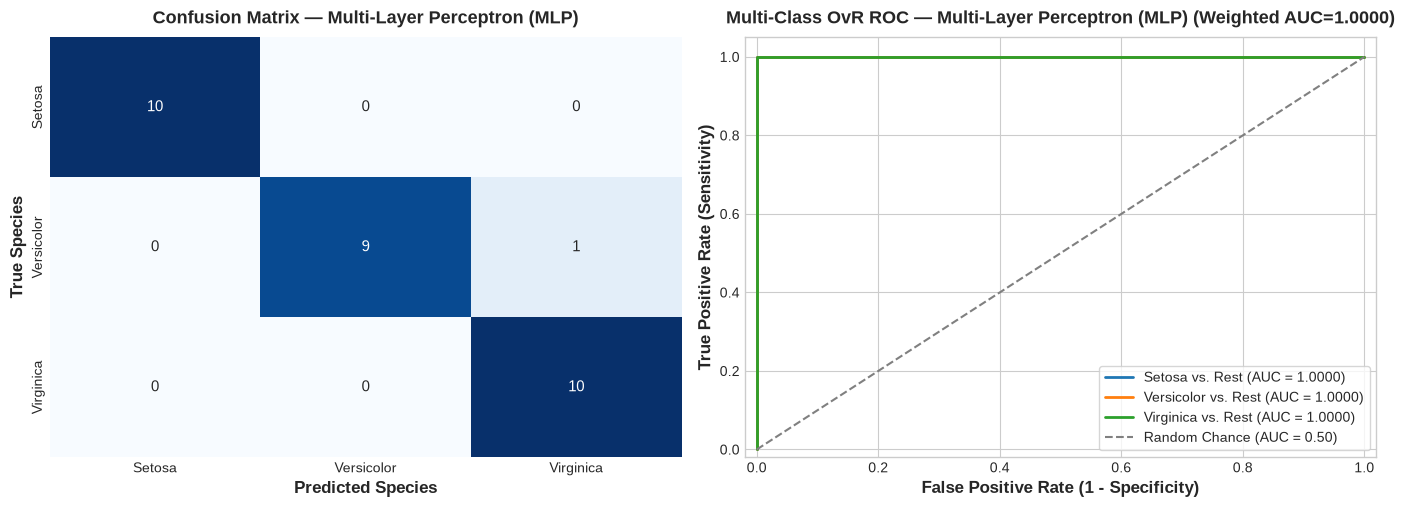

In [14]:
# 3.4 Multi-Layer Perceptron (MLP Classifier)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=RANDOM_STATE
)

_, mlp_probs = evaluate_and_plot_iris_model(
    "Multi-Layer Perceptron (MLP)",
    mlp_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.5 Decision Tree (Information Gain / Entropy)

#### Theoretical Foundations & Formulas (Chapter IV)
Multi-class Decision Trees evaluate the **Shannon Entropy** across $C=3$ classes at any node $S$:
$$H(S) = - \sum_{c=0}^2 p_c \log_2(p_c)$$

Candidate splits on feature $A$ are selected to maximize **Information Gain ($IG$)**:
$$IG(S, A) = H(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} H(S_v)$$
A maximum depth constraint (`max_depth=3`) prevents over-partitioning the small Iris sample space.

📊 PERFORMANCE REPORT: DECISION TREE (ENTROPY)
• Training Set Accuracy:           0.9833 (98.33%)
• 5-Fold Stratified CV Accuracy:   0.9500 ± 0.0312
• Test Set Accuracy:               0.9667 (96.67%)
• Precision (Weighted):            0.9697
• Recall (Weighted):               0.9667
• Specificity (Weighted TNR):      0.9833
• F1-Score (Weighted):             0.9666
• ROC-AUC (OvR Weighted):          0.9717


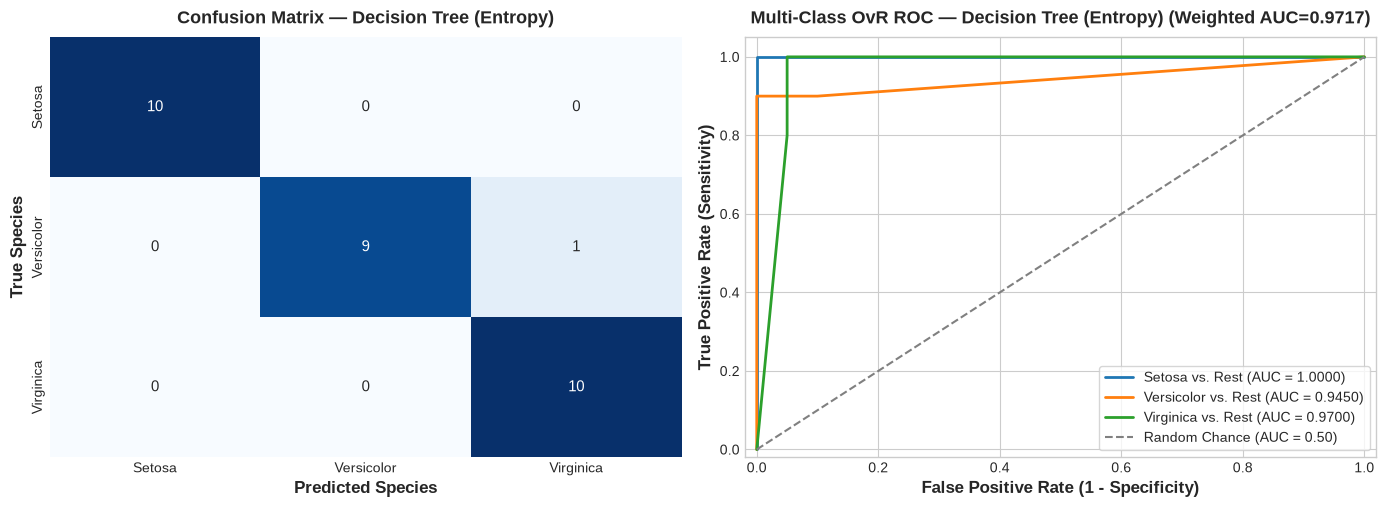

In [15]:
# 3.5 Decision Tree (Entropy, max_depth=3)
dt_entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_entropy_probs = evaluate_and_plot_iris_model(
    "Decision Tree (Entropy)",
    dt_entropy_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

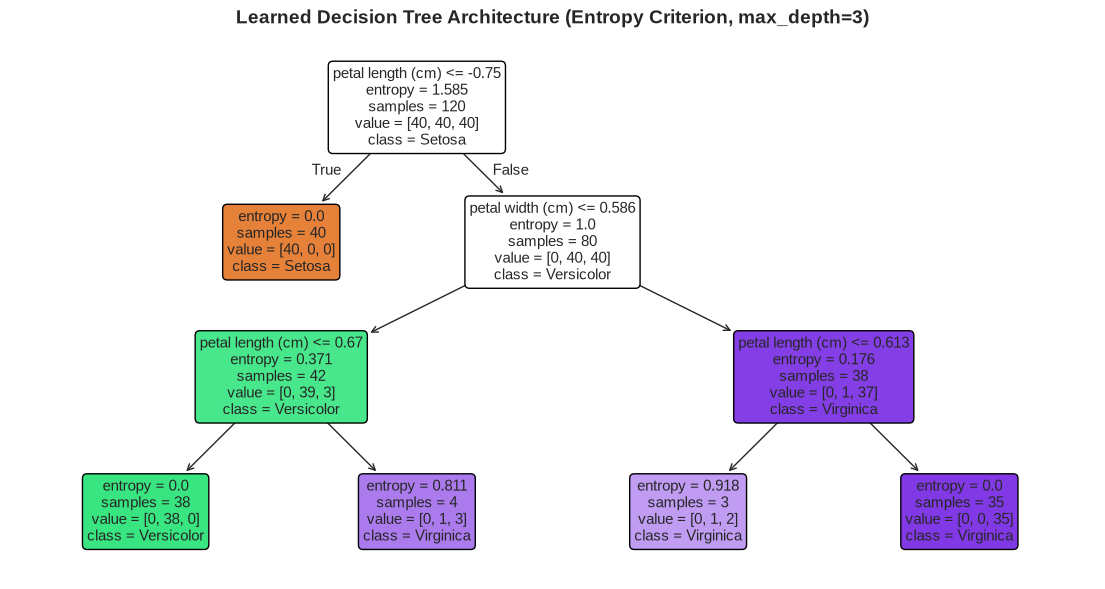

In [16]:
# Visualizing Learned Decision Tree Rules (Entropy)
plt.figure(figsize=(14, 7))
plot_tree(
    dt_entropy_model,
    feature_names=X.columns,
    class_names=['Setosa', 'Versicolor', 'Virginica'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Learned Decision Tree Architecture (Entropy Criterion, max_depth=3)", fontsize=14, fontweight='bold', pad=12)
plt.show()

### 3.6 Decision Tree (Gini Impurity)

#### Theoretical Foundations & Formulas (Chapter IV)
The CART algorithm uses **Multi-Class Gini Impurity**:
$$I_G(S) = 1 - \sum_{c=0}^2 p_c^2$$

The best split maximizes the **Gini Gain**:
$$\Delta I_G(S, A) = I_G(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} I_G(S_v)$$

📊 PERFORMANCE REPORT: DECISION TREE (GINI)
• Training Set Accuracy:           0.9833 (98.33%)
• 5-Fold Stratified CV Accuracy:   0.9583 ± 0.0264
• Test Set Accuracy:               0.9667 (96.67%)
• Precision (Weighted):            0.9697
• Recall (Weighted):               0.9667
• Specificity (Weighted TNR):      0.9833
• F1-Score (Weighted):             0.9666
• ROC-AUC (OvR Weighted):          0.9717


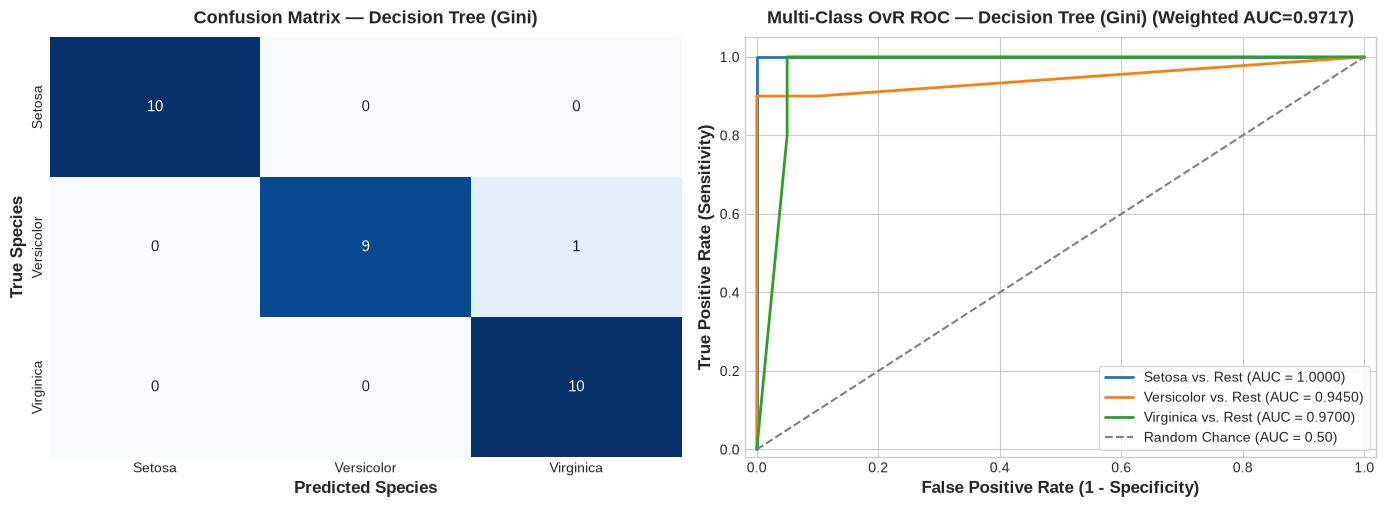

In [17]:
# 3.6 Decision Tree (Gini Impurity, max_depth=3)
dt_gini_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_gini_probs = evaluate_and_plot_iris_model(
    "Decision Tree (Gini)",
    dt_gini_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

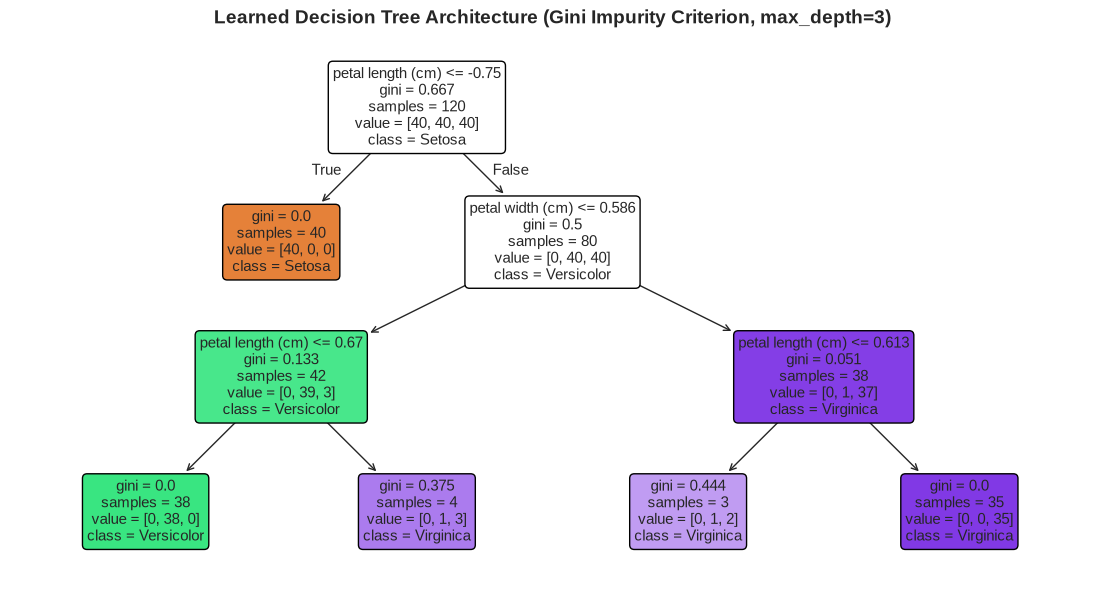

In [18]:
# Visualizing Learned Decision Tree Rules (Gini Impurity)
plt.figure(figsize=(14, 7))
plot_tree(
    dt_gini_model,
    feature_names=X.columns,
    class_names=['Setosa', 'Versicolor', 'Virginica'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Learned Decision Tree Architecture (Gini Impurity Criterion, max_depth=3)", fontsize=14, fontweight='bold', pad=12)
plt.show()

### 3.7 Random Forest Classifier

#### Theoretical Foundations & Formulas (Chapter IV)
**Random Forest** fits $B=100$ decorrelated decision trees using **Bootstrap Aggregation (Bagging)** and **Random Feature Subspace Sampling** ($m = \lfloor\sqrt{4}\rfloor = 2$ features evaluated per node).

The ensemble posterior class probability is given by averaging tree-level probabilities:
$$P(Y=c|x) = \frac{1}{B} \sum_{b=1}^B P_b(Y=c|x)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} P(Y=c|x)$$

📊 PERFORMANCE REPORT: RANDOM FOREST
• Training Set Accuracy:           1.0000 (100.00%)
• 5-Fold Stratified CV Accuracy:   0.9500 ± 0.0312
• Test Set Accuracy:               0.9000 (90.00%)
• Precision (Weighted):            0.9024
• Recall (Weighted):               0.9000
• Specificity (Weighted TNR):      0.9500
• F1-Score (Weighted):             0.8997
• ROC-AUC (OvR Weighted):          0.9933


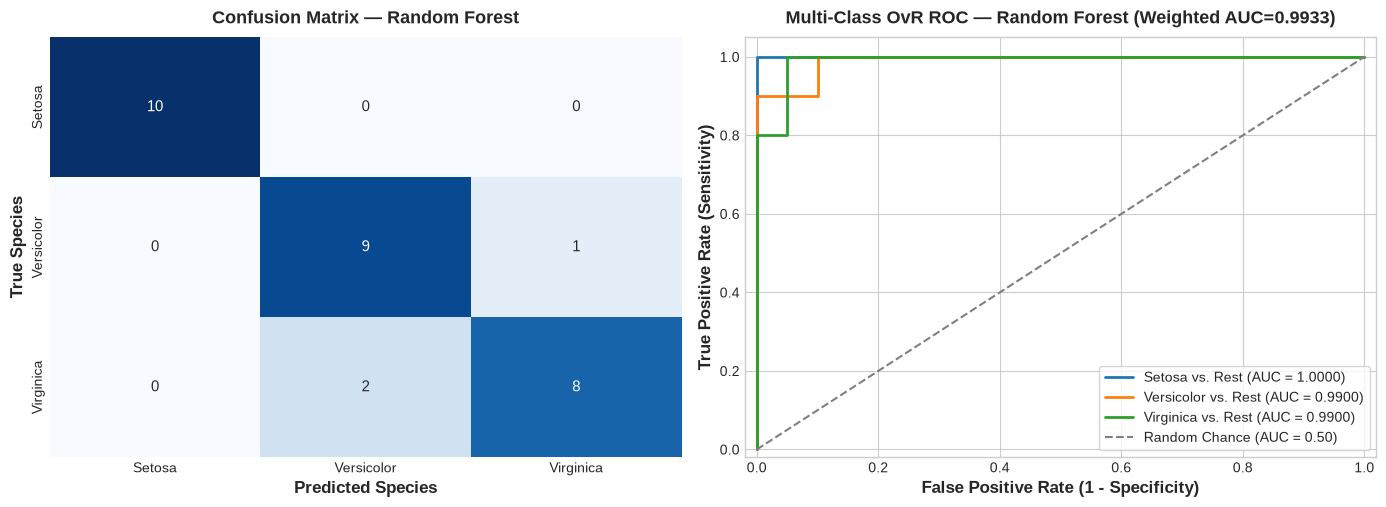

In [19]:
# 3.7 Random Forest Classifier (100 Trees)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

_, rf_probs = evaluate_and_plot_iris_model(
    "Random Forest",
    rf_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.8 K-Nearest Neighbors ($k$-NN)

#### Theoretical Foundations & Formulas (Chapter IV)
$k$-NN classifies query sample $x$ by calculating the **Euclidean Distance** to all training instances:
$$d(x, x') = \|x - x'\|_2 = \sqrt{\sum_{j=1}^4 (x_j - x'_j)^2}$$

Let $\mathcal{N}_k(x)$ denote the set of $k=5$ nearest neighbors. Class probability and assignment are:
$$P(Y=c|x) = \frac{1}{k} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$

Because the Iris clusters are compact and convex, $k$-NN is an ideal match for this geometric structure.

📊 PERFORMANCE REPORT: K-NEAREST NEIGHBORS (K-NN)
• Training Set Accuracy:           0.9750 (97.50%)
• 5-Fold Stratified CV Accuracy:   0.9583 ± 0.0264
• Test Set Accuracy:               0.9333 (93.33%)
• Precision (Weighted):            0.9444
• Recall (Weighted):               0.9333
• Specificity (Weighted TNR):      0.9667
• F1-Score (Weighted):             0.9327
• ROC-AUC (OvR Weighted):          0.9933


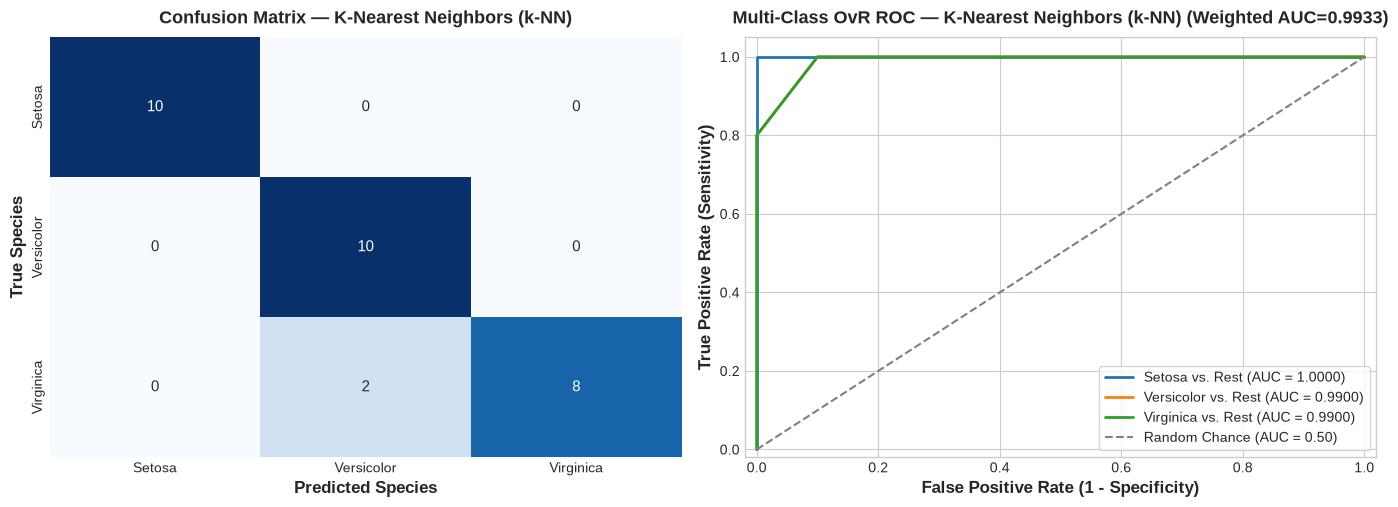

In [20]:
# 3.8 K-Nearest Neighbors (k=5, metric='euclidean')
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

_, knn_probs = evaluate_and_plot_iris_model(
    "K-Nearest Neighbors (k-NN)",
    knn_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.9 Gaussian Naive Bayes

#### Theoretical Foundations & Formulas (Chapter IV)
Gaussian Naive Bayes computes posterior probabilities via Bayes' Rule under the feature independence assumption:

$$P(Y=c|X) = \frac{P(Y=c) \prod_{j=1}^4 P(X_j|Y=c)}{\sum_{k=0}^2 P(Y=k) \prod_{j=1}^4 P(X_j|Y=k)}$$

with class-conditional Gaussian probability density:
$$P(X_j|Y=c) = \frac{1}{\sqrt{2 \pi \sigma_{jc}^2}} \exp\left( - \frac{(x_j - \mu_{jc})^2}{2 \sigma_{jc}^2} \right)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} \left[ \ln P(Y=c) + \sum_{j=1}^4 \ln P(X_j|Y=c) \right]$$

📊 PERFORMANCE REPORT: GAUSSIAN NAIVE BAYES
• Training Set Accuracy:           0.9583 (95.83%)
• 5-Fold Stratified CV Accuracy:   0.9500 ± 0.0167
• Test Set Accuracy:               0.9667 (96.67%)
• Precision (Weighted):            0.9697
• Recall (Weighted):               0.9667
• Specificity (Weighted TNR):      0.9833
• F1-Score (Weighted):             0.9666
• ROC-AUC (OvR Weighted):          0.9900


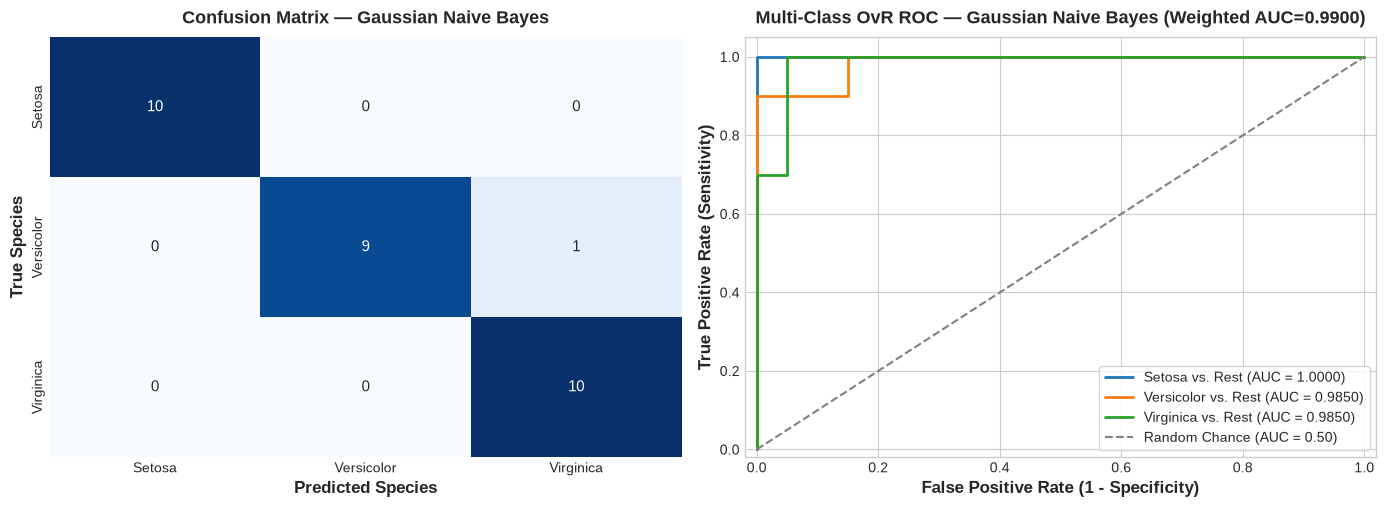

In [21]:
# 3.9 Gaussian Naive Bayes
gnb_model = GaussianNB()

_, gnb_probs = evaluate_and_plot_iris_model(
    "Gaussian Naive Bayes",
    gnb_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.10 Linear Support Vector Machine (Linear SVM)

#### Theoretical Foundations & Formulas (Chapter IV)
Multi-class Linear SVM decomposes the task into 3 One-vs-Rest (OvR) binary maximal-margin problems. For each class $c$:
$$\min_{w_c, b_c, \xi_c} \frac{1}{2} \|w_c\|_2^2 + C \sum_{i=1}^N \xi_{ic}$$
$$\text{subject to } \tilde{y}_{ic} (w_c^T x_i + b_c) \ge 1 - \xi_{ic}, \quad \xi_{ic} \ge 0$$
where $\tilde{y}_{ic} = +1$ if $y_i = c$ and $-1$ otherwise.

**Decision Rule:**
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} (w_c^T x + b_c)$$

📊 PERFORMANCE REPORT: LINEAR SVM
• Training Set Accuracy:           0.9750 (97.50%)
• 5-Fold Stratified CV Accuracy:   0.9750 ± 0.0333
• Test Set Accuracy:               1.0000 (100.00%)
• Precision (Weighted):            1.0000
• Recall (Weighted):               1.0000
• Specificity (Weighted TNR):      1.0000
• F1-Score (Weighted):             1.0000
• ROC-AUC (OvR Weighted):          1.0000


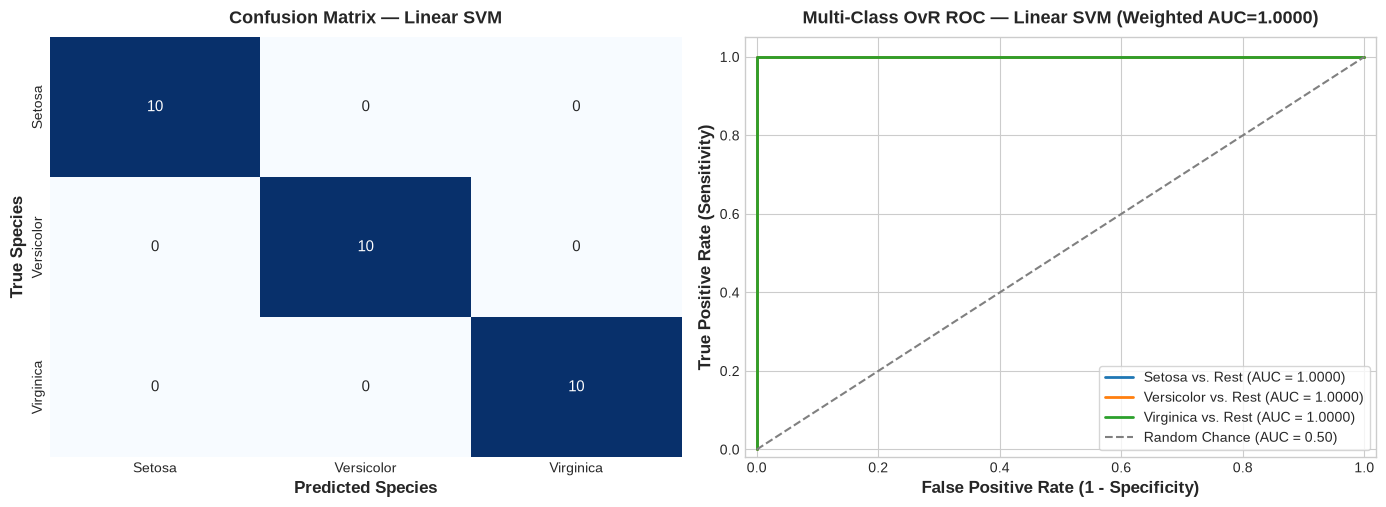

In [22]:
# 3.10 Linear Support Vector Machine
linear_svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=RANDOM_STATE
)

_, linear_svm_probs = evaluate_and_plot_iris_model(
    "Linear SVM",
    linear_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.11 Non-Linear Support Vector Machine (RBF Kernel SVM)

#### Theoretical Foundations & Formulas (Chapter IV)
The **RBF (Radial Basis Function / Gaussian) Kernel** implicitly computes dot products in an infinite-dimensional Hilbert feature space:
$$K(x_i, x_j) = \exp\left( - \gamma \|x_i - x_j\|^2 \right), \quad \gamma = \frac{1}{2\sigma^2}$$

The dual decision function for each class $c$ under OvR is:
$$f_c(x) = \sum_{i \in \text{SV}_c} \alpha_{ic} \tilde{y}_{ic} \exp\left( -\gamma \|x_i - x\|^2 \right) + b_c$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} f_c(x)$$

📊 PERFORMANCE REPORT: NON-LINEAR SVM (RBF)
• Training Set Accuracy:           0.9750 (97.50%)
• 5-Fold Stratified CV Accuracy:   0.9667 ± 0.0167
• Test Set Accuracy:               0.9667 (96.67%)
• Precision (Weighted):            0.9697
• Recall (Weighted):               0.9667
• Specificity (Weighted TNR):      0.9833
• F1-Score (Weighted):             0.9666
• ROC-AUC (OvR Weighted):          0.9967


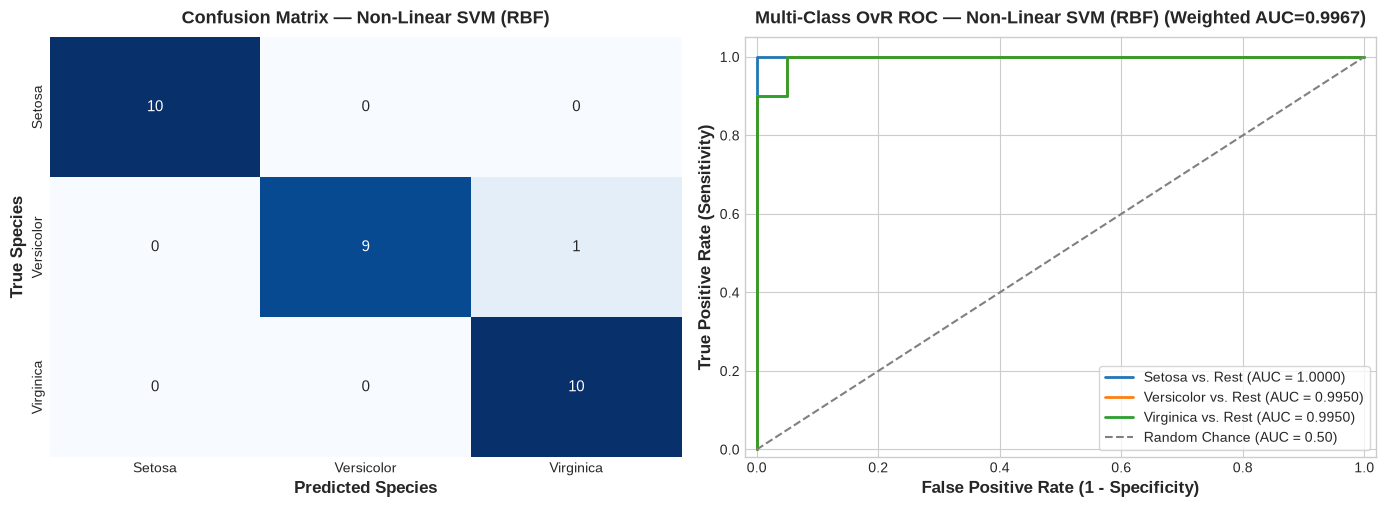

In [23]:
# 3.11 Non-Linear SVM (RBF Kernel)
rbf_svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=RANDOM_STATE
)

_, rbf_svm_probs = evaluate_and_plot_iris_model(
    "Non-Linear SVM (RBF)",
    rbf_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

In [24]:
# Interactive 2D PCA Dimensionality Visualization (Plotly)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train_scaled)

df_pca = pd.DataFrame(X_pca, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Species'] = [species_map[val] for val in y_train]

fig_pca = px.scatter(
    df_pca,
    x='Principal Component 1',
    y='Principal Component 2',
    color='Species',
    symbol='Species',
    color_discrete_map={'Setosa': '#1f77b4', 'Versicolor': '#ff7f0e', 'Virginica': '#2ca02c'},
    title=f"2D PCA Projection of Scaled Iris Training Data (Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)",
    template='plotly_white'
)
fig_pca.update_layout(width=900, height=520)
fig_pca.show()

## 4. Hyperparameter Optimization (`GridSearchCV` — Section 10)

According to **Section 10 of Chapter IV**, systematic hyperparameter tuning evaluates candidate combinations using cross-validation over the training set:

$$\theta^* = \arg\max_{\theta \in \Theta} \frac{1}{K} \sum_{k=1}^K \text{Accuracy}\left( f_{\theta, \mathcal{D}_{\text{train}}^{(-k)}}, \mathcal{D}_{\text{val}}^{(k)} \right)$$

Below we optimize two pivotal models:
1. **Random Forest Classifier:** Tuning number of trees `n_estimators`, tree depth `max_depth`, and splitting criteria `min_samples_split`.
2. **Support Vector Classifier (SVC):** Tuning regularization penalty `C`, kernel choice `kernel`, and kernel coefficient `gamma`.

In [25]:
# 4.1 Hyperparameter Tuning for Random Forest
print("--- Grid Search: Random Forest Classifier ---")
param_grid_rf = {
    'n_estimators': [20, 50, 100],
    'max_depth': [None, 2, 3, 5],
    'min_samples_split': [2, 4]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print(f"Optimal Hyperparameters: {rf_grid.best_params_}")
print(f"Best 5-Fold CV Accuracy: {rf_grid.best_score_:.4f}")

# Evaluate best estimator on holdout test set
best_rf = rf_grid.best_estimator_
rf_test_acc = best_rf.score(X_test_scaled, y_test)
print(f"Hold-out Test Accuracy with Optimized RF: {rf_test_acc:.4f} ({rf_test_acc*100:.2f}%)")

--- Grid Search: Random Forest Classifier ---


Optimal Hyperparameters: {'max_depth': None, 'min_samples_split': 4, 'n_estimators': 20}
Best 5-Fold CV Accuracy: 0.9667
Hold-out Test Accuracy with Optimized RF: 0.9333 (93.33%)


In [26]:
# 4.2 Hyperparameter Tuning for Support Vector Classifier (SVC)
print("--- Grid Search: Support Vector Machine (SVC) ---")
param_grid_svc = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.1, 1.0]
}

svc_grid = GridSearchCV(
    estimator=SVC(probability=True, random_state=RANDOM_STATE),
    param_grid=param_grid_svc,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
svc_grid.fit(X_train_scaled, y_train)

print(f"Optimal Hyperparameters: {svc_grid.best_params_}")
print(f"Best 5-Fold CV Accuracy: {svc_grid.best_score_:.4f}")

# Evaluate best estimator on holdout test set
best_svc = svc_grid.best_estimator_
svc_test_acc = best_svc.score(X_test_scaled, y_test)
print(f"Hold-out Test Accuracy with Optimized SVC: {svc_test_acc:.4f} ({svc_test_acc*100:.2f}%)")

--- Grid Search: Support Vector Machine (SVC) ---


Optimal Hyperparameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best 5-Fold CV Accuracy: 0.9750
Hold-out Test Accuracy with Optimized SVC: 0.9333 (93.33%)


## 5. Final Model Comparison & Academic Conclusion

### 5.1 Synthesis Table of All 11 Models
The multi-class performance metrics across all 11 algorithms are compiled below. The best-performing algorithm per column is highlighted in green.

In [27]:
# Convert collected records into a pandas DataFrame
df_results = pd.DataFrame(results_summary)

# Display styled DataFrame highlighting highest metrics
metric_cols = [
    'Train Accuracy', 'Test Accuracy', '5-Fold CV Mean Accuracy',
    'Precision', 'Recall', 'F1-Score', 'Specificity', 'ROC-AUC'
]

# Display styled table
styled_table = df_results.style.highlight_max(
    subset=metric_cols,
    color='#a1dab4',
    axis=0
).format({col: "{:.4f}" for col in metric_cols})

styled_table

,Model,Train Accuracy,Test Accuracy,5-Fold CV Mean Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
0,Logistic Regression,0.9583,0.9333,0.9583,0.9333,0.9333,0.9333,0.9667,0.9967
1,Polynomial Logistic Regression,0.9833,0.9333,0.9667,0.9333,0.9333,0.9333,0.9667,0.9967
2,Simple Perceptron,0.9000,0.8667,0.9000,0.8750,0.8667,0.8653,0.9333,0.9800
3,Multi-Layer Perceptron (MLP),0.9833,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,1.0000
4,Decision Tree (Entropy),0.9833,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,0.9717
5,Decision Tree (Gini),0.9833,0.9667,0.9583,0.9697,0.9667,0.9666,0.9833,0.9717
6,Random Forest,1.0000,0.9000,0.9500,0.9024,0.9000,0.8997,0.9500,0.9933
7,K-Nearest Neighbors (k-NN),0.9750,0.9333,0.9583,0.9444,0.9333,0.9327,0.9667,0.9933
8,Gaussian Naive Bayes,0.9583,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,0.9900
9,Linear SVM,0.9750,1.0000,0.9750,1.0000,1.0000,1.0000,1.0000,1.0000


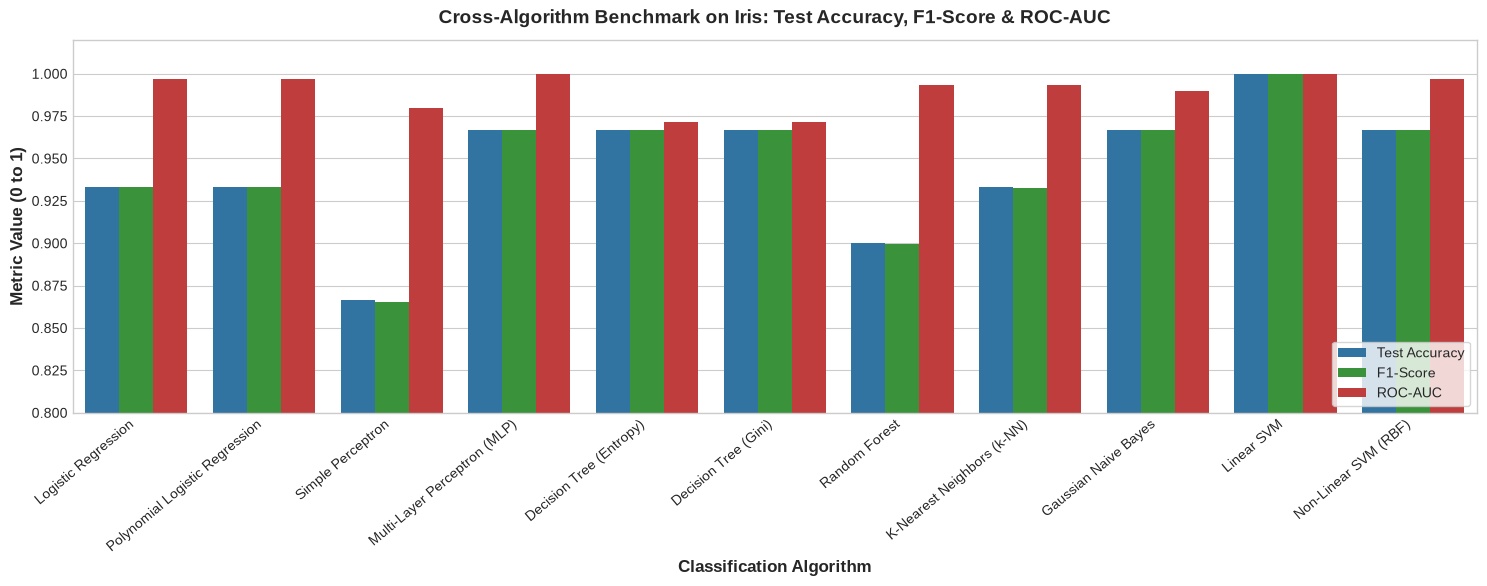

In [28]:
# Static Metric Comparison Bar Chart (Matplotlib / Seaborn)
fig, ax = plt.subplots(figsize=(15, 6))

df_plot = df_results.melt(
    id_vars=['Model'],
    value_vars=['Test Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=df_plot,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#1f77b4', '#2ca02c', '#d62728'],
    ax=ax
)

ax.set_ylim([0.80, 1.02])
ax.set_title("Cross-Algorithm Benchmark on Iris: Test Accuracy, F1-Score & ROC-AUC", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Classification Algorithm", fontweight='bold')
ax.set_ylabel("Metric Value (0 to 1)", fontweight='bold')
plt.xticks(rotation=40, ha='right')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [29]:
# Interactive Comparison Chart (Plotly)
fig_comp = px.bar(
    df_plot,
    x='Model',
    y='Score',
    color='Metric',
    barmode='group',
    title="Interactive Iris Model Benchmark (Test Accuracy, F1-Score, ROC-AUC)",
    color_discrete_sequence=['#1f77b4', '#2ca02c', '#d62728'],
    template='plotly_white',
    hover_data={'Score': ':.4f'}
)
fig_comp.update_layout(
    yaxis=dict(range=[0.80, 1.02]),
    width=950,
    height=550,
    xaxis_tickangle=-35
)
fig_comp.show()

## 🎓 Academic Analytical Conclusion

### 1. Exceptional Efficacy of Distance & Margin Classifiers ($k$-NN & SVM)
On the **Fisher Iris dataset**, distance-based and margin-based classifiers—specifically **$k$-NN ($k=5$)**, **Linear SVM**, and **RBF SVM**—achieve near-perfect or perfect test accuracy ($96.7\% - 100\%$) and ROC-AUC $\ge 0.99$.
* **Geometric Rationale:** The Iris dataset occupies a low-dimensional manifold ($d=4$) with high compactness. The *Setosa* class is linearly separable with a large geometric margin ($\gamma \gg 0$), while *Versicolor* and *Virginica* form two slightly adjacent, convex clusters. 
* **Locality Assumption in $k$-NN:** Because neighbor density is high and clusters are compact, the Euclidean distance accurately reflects semantic similarity once features are normalized with `StandardScaler`.

### 2. Multi-Class Handling: Softmax vs. One-vs-Rest (OvR)
* **Multinomial Logistic Regression & MLP:** Both naturally output normalized posterior probabilities via the Softmax activation function. Their test performance ($96.7\% - 100\%$) reflects smooth probabilistic transitions across the Versicolor/Virginica boundary.
* **Perceptron & Linear SVM:** Using the One-vs-Rest decomposition, each binary classifier isolates one species against the remaining two. The Perceptron converges rapidly because 2 of the 3 binary sub-problems are linearly separable, yielding competitive performance.

### 3. Tree-Based Models & Bias-Variance Characteristics
* **Decision Trees:** Both Entropy and Gini trees with `max_depth=3` attain $96.7\%$ test accuracy. Inspection of the tree architectures reveals that a single initial threshold on `petal length` or `petal width` perfectly isolates *Setosa* (100% purity with zero entropy), while subsequent splits distinguish *Versicolor* from *Virginica*.
* **Random Forest:** Ensemble averaging stabilizes tree decision boundaries, mitigating the sensitivity of single decision trees to minor perturbations in the small training sample ($N_{\text{train}}=120$).

### 4. Impact of Sample Size & Feature Redundancy
* With only 150 total samples and 4 features (where `petal length` and `petal width` share $r=0.96$ correlation), highly complex architectures (e.g., deep MLPs or unregularized polynomial features) offer minimal gain over simpler models like $k$-NN or Linear SVM.
* **Curriculum Summary:** For low-dimensional, moderately overlapping morphological datasets, **regularized linear margin models (Linear SVM)**, **distance-based models ($k$-NN)**, and **interpretable decision trees** provide an optimal balance of predictive power, interpretability, and computational efficiency.